In [35]:
import pandas as pd
import numpy as np
from functions import read_squid_file
from functions import determine_critical_temp
from functions import determine_critical_field
import matplotlib.pyplot as plt
import os
import statistics

In [36]:
#=======================================================================
# matplotlib rc — academic / journal style
#=======================================================================
plt.rcParams.update({
    "font.family":       "serif",
    "font.size":         10,
    "axes.labelsize":    10,
    "axes.titlesize":    10,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.fontsize":   9,
    "lines.linewidth":   1.0,
    "axes.linewidth":    0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.5,
    "ytick.minor.width": 0.5,
    "xtick.major.size":  4.0,
    "ytick.major.size":  4.0,
    "xtick.minor.size":  2.0,
    "ytick.minor.size":  2.0,
    "xtick.direction":   "in",
    "ytick.direction":   "in",
    "xtick.top":         True,
    "ytick.right":       True,
    "axes.grid":         True,
    "grid.color":        "#CCCCCC",
    "grid.linewidth":    0.4,
    "grid.linestyle":    "--",
    "grid.alpha":        0.6,
    "axes.axisbelow":    True,
    "figure.facecolor":  "white",
    "figure.figsize":    [7,4],
    "axes.facecolor":    "white",
    "savefig.dpi":       600,
    "savefig.bbox":      "tight",
    "savefig.facecolor": "white",
    "figure.dpi":        150,
    "legend.framealpha": 0.9,
    "legend.edgecolor":  "#AAAAAA",
    "legend.frameon":    True,
})

In [37]:
from pathlib import Path
runs = {}
pathlist = Path(
    "data/2026/10/26-10-15 Pb Analysis Folder fixed temp"
).glob("**/*.dat")
for path in sorted(pathlist):
    run_number = path.stem[-5:]
    runs[run_number] = read_squid_file(str(path))
for run_number, data in runs.items():
    print(f"Run {run_number}")

Run 00001
Run 00002
Run 00003


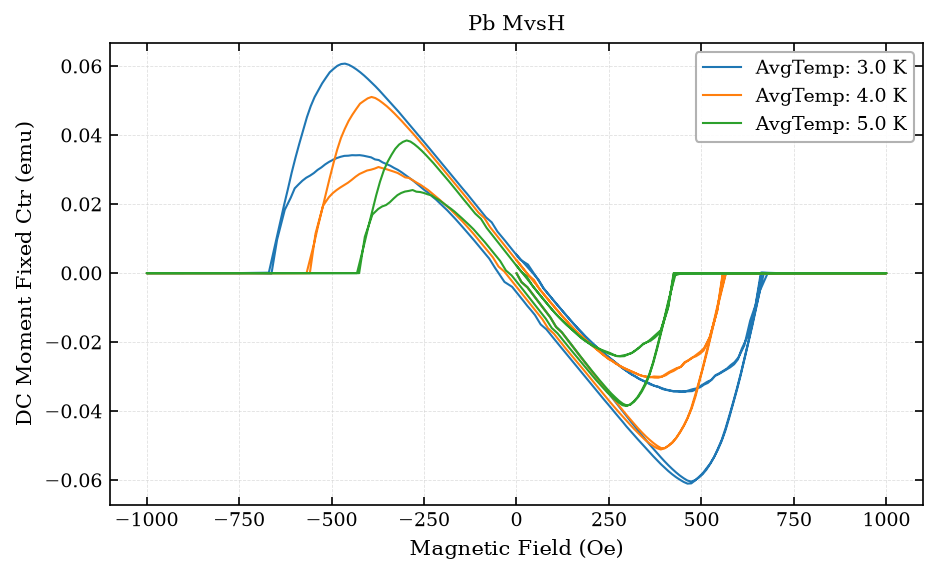

In [38]:
for run_number, dataframe in runs.items():
    temp = np.mean(dataframe["Temperature (K)"])
    # crit_temp, fitted_line, _ = determine_critical_temp(dataframe)
    # plt.axvline(crit_temp, color="tab:grey", linestyle="--", label=f"{crit_temp:.3f} K")
    plt.plot(
        dataframe["Magnetic Field (Oe)"],
        dataframe["DC Moment Fixed Ctr (emu)"],
        label=f"AvgTemp: {temp:.1f} K",
    )
    
plt.title("Pb MvsH")
plt.xlabel("Magnetic Field (Oe)")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.legend()
plt.show()

In [39]:
# def determine_critical_field(dataframe: pd.DataFrame, threshold: float = 0.02):
#     df = dataframe.sort_values("Magnetic Field (Oe)")
#     field = df["Magnetic Field (Oe)"].to_numpy()
#     moment = df["DC Moment Fixed Ctr (emu)"].to_numpy()
#     cutoff  = threshold * np.max(np.abs(moment))

#     field_pos = field[moment < -cutoff].max()   
#     field_neg = field[moment > cutoff].min()  
#     f_crit = (field_pos - field_neg) / 2
#     return f_crit, field_pos, field_neg



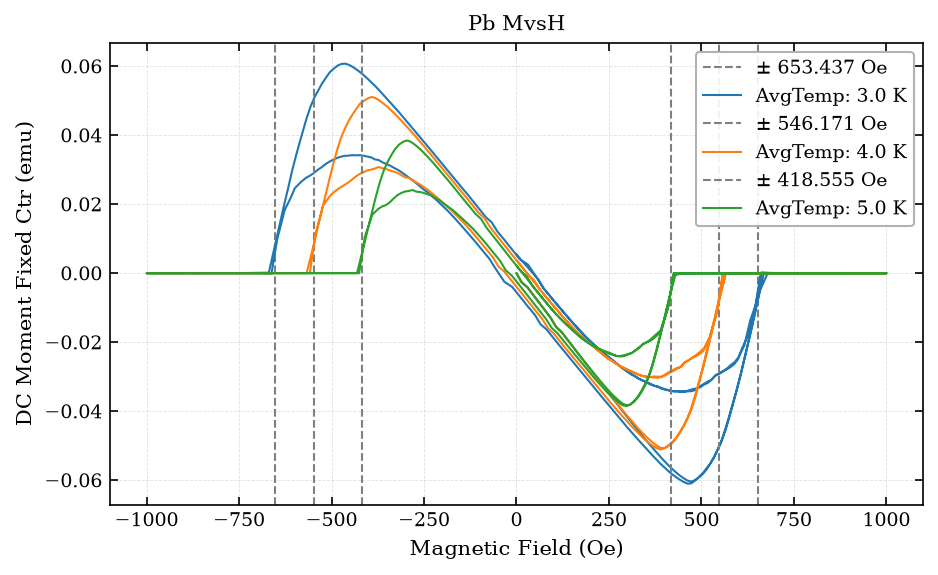

In [40]:
for run_number, dataframe in runs.items():
    temp = np.mean(dataframe["Temperature (K)"])
    crit_field, _, _ = determine_critical_field(dataframe, 0.005)
    plt.axvline(crit_field, color="tab:grey", linestyle="--", label = rf"$\pm$ {crit_field:.3f} Oe")
    plt.axvline(-crit_field, color="tab:grey", linestyle="--",)

    plt.plot(
        dataframe["Magnetic Field (Oe)"],
        dataframe["DC Moment Fixed Ctr (emu)"],
        label=f"AvgTemp: {temp:.1f} K",
    )
    
plt.title("Pb MvsH")
plt.xlabel("Magnetic Field (Oe)")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.legend()
plt.show()

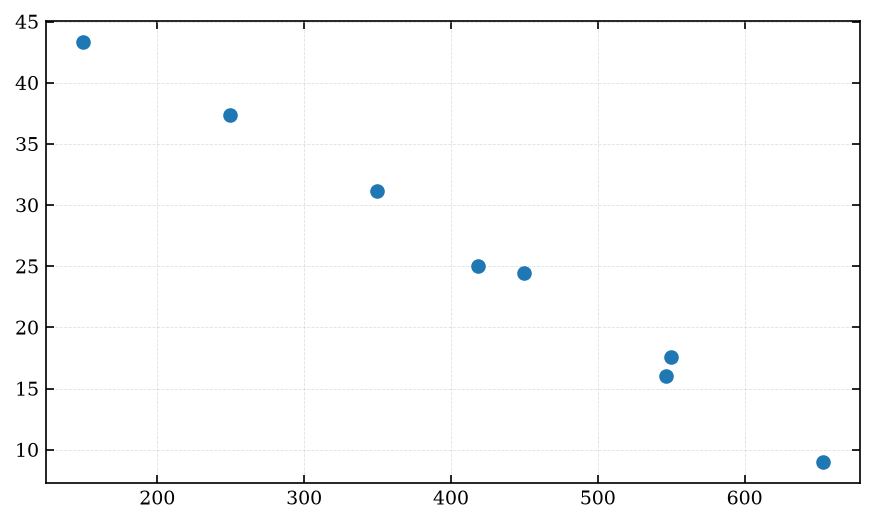

In [42]:
pb_temps = [3,4,5,
            6.583,6.113,5.584,4.948,4.195]
pb_fields = [653.437, 546.171, 418.555,
             149.6,249.6,349.8,449.8,549.7]
pb_temps = np.array(pb_temps)
plt.scatter(pb_fields,pb_temps**2)
